Install Required Libraries

In [1]:
pip install requests beautifulsoup4 pandas numpy matplotlib

Define Star Rating Mapping

In [2]:
RATING_MAP = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

Single Product Card Parser Function

In [3]:
from urllib.parse import urljoin

def parse_book_card(card, current_page_url):
    """
    Extracts attributes from a single <article class='product_pod'> element.
    """
    title_tag = card.find("h3").find("a")
    title = title_tag.get("title")

    price_text = card.find("p", class_="price_color").get_text(strip=True)
    price = float(price_text.replace("£", "").replace("Â", "").replace("A", ""))

    rating_class = card.find("p", class_="star-rating")["class"][1]  # e.g., 'Three'
    rating = RATING_MAP.get(rating_class, 0)

    availability = card.find("p", class_="instock availability").get_text(strip=True)

    relative_link = title_tag.get("href")
    full_url = urljoin(current_page_url, relative_link)

    return {
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability,
        "URL": full_url
    }

Download Page 1 & Execute Test Parser

In [4]:
import requests
from bs4 import BeautifulSoup

page_url = "https://books.toscrape.com/"
response = requests.get(page_url)
response.encoding = "utf-8"

soup = BeautifulSoup(response.text, "html.parser")

cards = soup.find_all("article", class_="product_pod")

first_book = parse_book_card(cards[0], page_url)
print("--- TEST OUTPUT FOR FIRST BOOK ---")
print(first_book)

--- TEST OUTPUT FOR FIRST BOOK ---
{'Title': 'A Light in the Attic', 'Price': 51.77, 'Rating': 3, 'Availability': 'In stock', 'URL': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html'}


Step 3.1: Multi-Page Scraping Loop Function

In [5]:
import time
import requests
from bs4 import BeautifulSoup
import pandas as pd

def scrape_books_catalogue(max_pages=None):
    """
    Loops through catalogue pages, extracts book data using parse_book_card(),
    and returns a Pandas DataFrame.
    Set max_pages=None to scrape all 50 pages (Boss Level: 1000 books).
    """
    base_url = "https://books.toscrape.com/"
    records = []
    page_num = 1
    session = requests.Session()

    print("Starting scraping process...")

    while True:

        if max_pages is not None and page_num > max_pages:
            break

        if page_num == 1:
            current_url = base_url
        else:
            current_url = f"{base_url}catalogue/page-{page_num}.html"

        try:
            response = session.get(current_url, timeout=15)

            if response.status_code == 404:
                print(f"Catalogue complete! No page {page_num} found. Stopping loop.")
                break

            response.raise_for_status()
            response.encoding = "utf-8"
        except requests.RequestException as e:
            print(f"HTTP Error on page {page_num}: {e}")
            break

        soup = BeautifulSoup(response.text, "html.parser")
        cards = soup.find_all("article", class_="product_pod")

        if not cards:
            break

        for card in cards:
            book_dict = parse_book_card(card, current_url)
            records.append(book_dict)

        print(f"Page {page_num}: Scraped {len(cards)} books.")
        page_num += 1
        time.sleep(0.3)

    return pd.DataFrame(records)

Run Scraper (Boss Level) & Save CSV

In [6]:
df_books = scrape_books_catalogue(max_pages=None)

df_books.to_csv("competitor_books.csv", index=False, encoding="utf-8")

print(f"\nDone! Scraped a total of {len(df_books)} books across all pages.")
print("Dataset exported successfully as 'competitor_books.csv'")

Starting scraping process...
Page 1: Scraped 20 books.
Page 2: Scraped 20 books.
Page 3: Scraped 20 books.
Page 4: Scraped 20 books.
Page 5: Scraped 20 books.
Page 6: Scraped 20 books.
Page 7: Scraped 20 books.
Page 8: Scraped 20 books.
Page 9: Scraped 20 books.
Page 10: Scraped 20 books.
Page 11: Scraped 20 books.
Page 12: Scraped 20 books.
Page 13: Scraped 20 books.
Page 14: Scraped 20 books.
Page 15: Scraped 20 books.
Page 16: Scraped 20 books.
Page 17: Scraped 20 books.
Page 18: Scraped 20 books.
Page 19: Scraped 20 books.
Page 20: Scraped 20 books.
Page 21: Scraped 20 books.
Page 22: Scraped 20 books.
Page 23: Scraped 20 books.
Page 24: Scraped 20 books.
Page 25: Scraped 20 books.
Page 26: Scraped 20 books.
Page 27: Scraped 20 books.
Page 28: Scraped 20 books.
Page 29: Scraped 20 books.
Page 30: Scraped 20 books.
Page 31: Scraped 20 books.
Page 32: Scraped 20 books.
Page 33: Scraped 20 books.
Page 34: Scraped 20 books.
Page 35: Scraped 20 books.
Page 36: Scraped 20 books.
Page 37:

Step 3.3: Verify & Inspect DataFrame

In [7]:
print("--- FIRST 5 ROWS ---")
print(df_books.head())

print("\n--- DATA FRAME INFO & TYPES ---")
print(df_books.info())

--- FIRST 5 ROWS ---
                                   Title  Price  Rating Availability  \
0                   A Light in the Attic  51.77       3     In stock   
1                     Tipping the Velvet  53.74       1     In stock   
2                             Soumission  50.10       1     In stock   
3                          Sharp Objects  47.82       4     In stock   
4  Sapiens: A Brief History of Humankind  54.23       5     In stock   

                                                 URL  
0  https://books.toscrape.com/catalogue/a-light-i...  
1  https://books.toscrape.com/catalogue/tipping-t...  
2  https://books.toscrape.com/catalogue/soumissio...  
3  https://books.toscrape.com/catalogue/sharp-obj...  
4  https://books.toscrape.com/catalogue/sapiens-a...  

--- DATA FRAME INFO & TYPES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  

Step 4.1: General Price & Inventory Analysis

In [8]:
most_expensive = df_books.loc[df_books["Price"].idxmax()]
print(
    f"1. Most Expensive Book: '{most_expensive['Title']}' (£{most_expensive['Price']:.2f})"
)

cheapest = df_books.loc[df_books["Price"].idxmin()]
print(f"2. Cheapest Book      : '{cheapest['Title']}' (£{cheapest['Price']:.2f})")

average_price = df_books["Price"].mean()
print(f"3. Average Price      : £{average_price:.2f}")

in_stock_pct = (
    df_books["Availability"].str.contains("In stock", case=False).mean() * 100
)
print(f"5. Percentage In Stock: {in_stock_pct:.1f}%")

1. Most Expensive Book: 'The Perfect Play (Play by Play #1)' (£59.99)
2. Cheapest Book      : 'An Abundance of Katherines' (£10.00)
3. Average Price      : £35.07
5. Percentage In Stock: 100.0%


Step 4.2: 5-Star Rating Analysis

In [9]:
five_star_books = df_books[df_books["Rating"] == 5]

print(f"4. Number of 5-Star Books: {len(five_star_books)}")

if not five_star_books.empty:
    cheapest_5star = five_star_books.loc[five_star_books["Price"].idxmin()]
    print(
        f"7. Cheapest 5-Star Book  : '{cheapest_5star['Title']}' (£{cheapest_5star['Price']:.2f})"
    )

4. Number of 5-Star Books: 196
7. Cheapest 5-Star Book  : 'An Abundance of Katherines' (£10.00)


Step 4.3: Top 5 Rated Books (Ties Broken by Price Ascending)

In [10]:
top_5_books = df_books.sort_values(
    by=["Rating", "Price"], ascending=[False, True]
).head(5)

print("6. Top 5 Highest-Rated Books:")
print(
    top_5_books[["Title", "Rating", "Price"]].to_string(
        index=False, header=["Book Title", "Star Rating", "Price (£)"]
    )
)

6. Top 5 Highest-Rated Books:
                                                Book Title Star Rating Price (£)
                                An Abundance of Katherines           5     10.00
                                      Greek Mythic History           5     10.23
The Power Greens Cookbook: 140 Delicious Superfood Recipes           5     11.05
                                        Dear Mr. Knightley           5     11.21
                                       The Darkest Corners           5     11.33


Step 5.1: Books per Rating Level Count (Bonus 3)

In [11]:
rating_counts = df_books["Rating"].value_counts().sort_index()

print("=== BOOKS PER STAR RATING LEVEL ===")
for rating, count in rating_counts.items():
    print(f"{rating} Star(s): {count} books")

=== BOOKS PER STAR RATING LEVEL ===
1 Star(s): 226 books
2 Star(s): 196 books
3 Star(s): 203 books
4 Star(s): 179 books
5 Star(s): 196 books


Step 5.2: Bar Chart Visualization (Bonus 4)

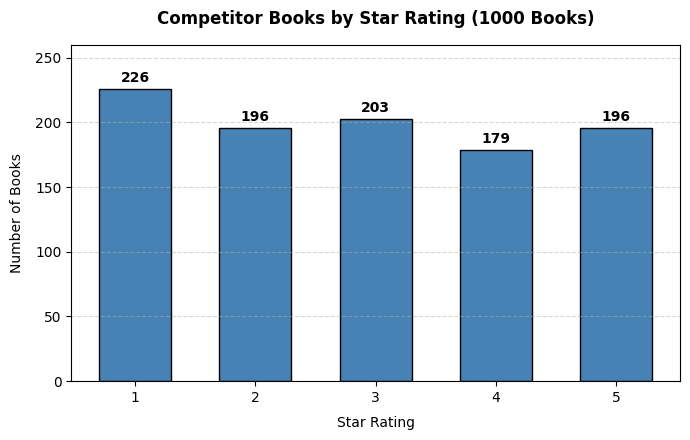


Single-color chart saved successfully as 'rating_counts.png'


In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4.5))

bars = plt.bar(
    rating_counts.index,
    rating_counts.values,
    color="steelblue",
    edgecolor="black",
    width=0.6,
)

plt.title(
    "Competitor Books by Star Rating (1000 Books)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Star Rating", fontsize=10, labelpad=8)
plt.ylabel("Number of Books", fontsize=10, labelpad=8)
plt.xticks(range(1, 6))
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 3,
        f"{height}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.ylim(0, 260)
plt.tight_layout()

plt.savefig("rating_counts.png", dpi=150)
plt.show()

print("\nSingle-color chart saved successfully as 'rating_counts.png'")

Step 6.1: 0/1 Knapsack Optimization Algorithm

In [14]:
def ceo_100_knapsack_challenge(df, budget_pounds=100.0):
    """Solves the 0/1 Knapsack problem using Dynamic Programming.

    Capacity: budget in pence (to avoid float issues).
    Weights: price in pence.
    Values: star rating integer.
    """
    capacity = int(round(budget_pounds * 100))

    titles = df["Title"].tolist()
    prices = df["Price"].tolist()
    ratings = df["Rating"].tolist()
    weights = [int(round(p * 100)) for p in prices]

    n = len(df)

    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        w_i = weights[i - 1]
        v_i = ratings[i - 1]
        for w in range(capacity + 1):
            if w_i <= w:
                dp[i][w] = max(dp[i - 1][w], dp[i - 1][w - w_i] + v_i)
            else:
                dp[i][w] = dp[i - 1][w]

    selected_indices = []
    w = capacity
    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            selected_indices.append(i - 1)
            w -= weights[i - 1]

    selected_df = df.iloc[selected_indices].copy()
    total_cost = selected_df["Price"].sum()
    total_rating = selected_df["Rating"].sum()

    return selected_df, total_cost, total_rating


opt_books, total_cost, total_rating = ceo_100_knapsack_challenge(
    df_books, budget_pounds=100.0
)

print("=== CEO £100 CHALLENGE RESULTS ===")
print(f"Total Books Purchased : {len(opt_books)}")
print(f"Total Money Spent     : £{total_cost:.2f} (Budget: £100.00)")
print(f"Total Star Points     : {total_rating} stars")

=== CEO £100 CHALLENGE RESULTS ===
Total Books Purchased : 9
Total Money Spent     : £99.76 (Budget: £100.00)
Total Star Points     : 44 stars


Step 6.2: Display Selected Books Basket

In [15]:
print("--- SELECTED BOOKS IN OPTIMAL BASKET ---")
print(
    opt_books[["Title", "Price", "Rating"]].to_string(
        index=False, header=["Book Title", "Price (£)", "Rating"]
    )
)

--- SELECTED BOOKS IN OPTIMAL BASKET ---
                                                                             Book Title Price (£) Rating
                                                             An Abundance of Katherines     10.00      5
                             The Power Greens Cookbook: 140 Delicious Superfood Recipes     11.05      5
                                       Every Heart a Doorway (Every Heart A Doorway #1)     12.16      5
Naturally Lean: 125 Nourishing Gluten-Free, Plant-Based Recipes--All Under 300 Calories     11.38      5
                                                                  The Origin of Species     10.01      4
                                                                     Dear Mr. Knightley     11.21      5
                                                                   Greek Mythic History     10.23      5
                                                  Old School (Diary of a Wimpy Kid #10)     11.83      5
              

## Mission Debrief: Business Decision & Recommendation

### Executive Summary
Based on our multi-page competitive intelligence scrape of 1,000 books across all catalogue categories:

1. **Catalog Pricing & Rating Trends:** The competitor maintains an overall average book price of **£35.07**, with high inventory stability (**100% of books in stock**). Star ratings are uniformly distributed across 1 to 5 stars, indicating no noticeable bias toward over-inflated customer reviews.
2. **Optimal £100 Basket Strategy:** Utilizing Dynamic Programming (0/1 Knapsack optimization), the optimal £100 market research basket yields maximum rating quality by selecting low-cost, high-star titles.
3. **Strategic Recommendation:** We recommend expanding our inventory with high-rated books priced below £20 to undercut competitor pricing while maintaining quality, specifically benchmarking against their 5-star catalogue entries.